# GRU (Gated Recurrent Unit) — Temelden Uygulamaya
### PyTorch ve Keras ile satır satır açıklamalı

**İçerik**
1. Neden GRU? RNN ve LSTM'den sonra gelen fikir
2. GRU algoritması: 2 kapı, tek hafıza
3. Elle küçük bir sayısal örnek (NumPy)
4. Veri hazırlama (gürültülü sinüs dalgası — RNN/LSTM notebook'larıyla aynı)
5. **PyTorch** ile GRU — elle yazılmış hücre, `nn.GRU` ile birebir doğrulama, eğitim
6. **Keras** ile GRU — `layers.GRU`
7. Karşılaştırma: RNN vs LSTM vs GRU

**Görev:** Bir sinüs dalgasının son 20 değerine bakıp **bir sonraki** değeri tahmin etmek.

## 1. Neden GRU?

| Model | Sorun / Çözüm |
|---|---|
| **RNN** | Hafıza her adımda tamamen yeniden yazılır → gradyan **kaybolur**, uzak geçmiş öğrenilemez. |
| **LSTM** | Ayrı bir hücre durumu $c_t$ ve 3 kapı ekler → uzun hafıza sağlar, ama **karmaşık** ve parametre sayısı yüksektir (≈ 4× RNN). |
| **GRU** | (Cho ve ark., 2014) LSTM'in fikrini **sadeleştirir**: ayrı hücre durumu yoktur, **2 kapı** vardır → daha az parametre (≈ 3× RNN), çoğu problemde LSTM'e yakın başarı. |

**GRU'nun ana fikri:** Yeni hafıza, eski hafıza ile aday hafızanın **ağırlıklı ortalamasıdır**. Bu ağırlığı da ağ kendisi öğrenir.
$$h_t = \underbrace{z_t}_{\text{ne kadar eski}} \odot h_{t-1} \;+\; \underbrace{(1 - z_t)}_{\text{ne kadar yeni}} \odot \tilde{h}_t$$

> **Benzetme:** Bir **ses mikseri** düşün. İki kanal var: "eski hafıza" ve "yeni bilgi". $z_t$ sürgüsü bu iki kanal arasında geçiş yapar.
> Sürgü 1'deyken yalnızca eski hafıza duyulur (bilgi korunur). Sürgü 0'dayken yalnızca yeni bilgi duyulur (hafıza yenilenir).

## 2. GRU algoritması

Her adımda girdi olarak $x_t$ ve önceki gizli durum $h_{t-1}$ gelir. LSTM'deki gibi ayrı bir $c_t$ **yoktur**.

### 2.1 İki kapı
| Ad | Formül | Görevi |
|---|---|---|
| **Sıfırlama kapısı** $r_t$ (reset) | $\sigma(W_r x_t + U_r h_{t-1} + b_r)$ | Aday hesaplanırken **geçmişin ne kadarına bakılsın**? (0 = geçmişi yok say) |
| **Güncelleme kapısı** $z_t$ (update) | $\sigma(W_z x_t + U_z h_{t-1} + b_z)$ | Eski hafızanın ne kadarı **korunsun**? (1 = hepsini koru) |

### 2.2 Aday hafıza ve güncelleme
$$\tilde{h}_t = \tanh\!\big(W_h x_t + r_t \odot (U_h h_{t-1} + b_{hn}) + b_h\big)$$
$$h_t = z_t \odot h_{t-1} + (1 - z_t) \odot \tilde{h}_t$$

- $r_t \approx 0$ olduğunda aday yalnızca şu anki girdiye bakar. Bu, "yeni bir bölüm başladı, geçmişi unut" demektir.
- $z_t \approx 1$ olduğunda $h_t \approx h_{t-1}$ olur: bilgi değişmeden bir sonraki adıma taşınır.

> **Not (gösterim farkı):** Orijinal makalede formül $h_t = (1-z_t)\,h_{t-1} + z_t\,\tilde{h}_t$ şeklindedir; yani $z$'nin rolü terstir.
> **PyTorch ve Keras** yukarıdaki biçimi kullanır ($z$ = eskiyi koru). Bu notebook da kütüphanelerle aynı gösterimi kullanıyor.
> Ayrıca $r_t$'nin $U_h h_{t-1}$ çarpımından **sonra** uygulanması da PyTorch'un ve Keras'ın varsayılanıdır (Keras'ta `reset_after=True`).

### 2.3 LSTM ile eşleştirme
| LSTM | GRU |
|---|---|
| Unut kapısı $f_t$ | $z_t$ |
| Girdi kapısı $i_t$ | $1 - z_t$ (tek kapıya bağlanmış!) |
| Çıkış kapısı $o_t$ | yok (hafızanın tamamı dışarıya verilir) |
| Hücre durumu $c_t$ + gizli durum $h_t$ | yalnız $h_t$ |

GRU'da unutma ve yazma **tek bir kapıyla birbirine bağlıdır**: ne kadar unutulursa o kadar yeni bilgi yazılır.

### 2.4 Neden gradyan kaybolmuyor?
$$\frac{\partial h_t}{\partial h_{t-1}} \ni z_t \quad\text{(doğrudan yol)}$$
$z_t \approx 1$ olduğunda gradyan, LSTM'deki taşıma bandına benzer şekilde **neredeyse hiç küçülmeden** geriye akar.

### 2.5 Akış diyagramı
```
 h_{t-1} ──┬──────────────(× z_t)──────────(+)──► h_t
           │                                ▲
           ├─► r_t ──┐                (× (1 − z_t))
           │         ▼                      ▲
 x_t ──────┴──► h̃_t = tanh(W x_t + r_t ⊙ U h_{t-1})
```

### 2.6 Parametre sayısı
3 blok (r, z, h̃) olduğu için parametre sayısı **≈ 3 × RNN**: $\;3 \times (H\cdot F + H\cdot H + 2H)$

## 3. Elle küçük bir sayısal örnek

Gizli boyut 1, girdi dizisi $[0.5,\ 0.8]$. Ağırlıklar elle seçildi.

In [1]:
import numpy as np                        # Sayısal hesaplama

def sigmoid(z):                           # 0-1 arasına sıkıştırır (kapılar için)
    return 1 / (1 + np.exp(-z))

# Her blok için (W: girdi ağırlığı, U: gizli durum ağırlığı, b: bias) — hepsi skaler (H=1)
W_r, U_r, b_r = 1.0, 0.5, 0.0             # Sıfırlama kapısı
W_z, U_z, b_z = 0.5, 0.5, 0.5             # Güncelleme kapısı (bias + → biraz "koruma" eğilimi)
W_h, U_h, b_h = 1.0, 0.5, 0.0             # Aday hafıza

x_dizi = [0.5, 0.8]                       # 2 adımlık girdi dizisi
h = 0.0                                   # h_0: hafıza boş (GRU'da c YOK, sadece h)

for t, x_t in enumerate(x_dizi, start=1):
    r = sigmoid(W_r * x_t + U_r * h + b_r)        # Sıfırlama: geçmişin ne kadarına bakılsın
    z = sigmoid(W_z * x_t + U_z * h + b_z)        # Güncelleme: eskinin ne kadarı korunsun
    h_aday = np.tanh(W_h * x_t + r * (U_h * h) + b_h)  # Aday: geçmiş r ile filtrelenmiş
    h = z * h + (1 - z) * h_aday                  # GRU'nun kalbi: eski ile yeninin ağırlıklı ortalaması
    print(f"t={t}: r={r:.3f}  z={z:.3f}  h̃={h_aday:.3f}  →  h_{t}={h:.4f}"
          f"   (= {z:.3f}·eski + {1 - z:.3f}·yeni)")

t=1: r=0.622  z=0.679  h̃=0.462  →  h_1=0.1483   (= 0.679·eski + 0.321·yeni)
t=2: r=0.706  z=0.726  h̃=0.692  →  h_2=0.2973   (= 0.726·eski + 0.274·yeni)


**Yorum:** $t=1$'de eski hafıza 0 olduğu için $h_1$ yalnızca adayın $(1-z_1)$ kadarıdır. $t=2$'de ise $h_2$, eski hafıza $h_1$ ile yeni aday arasında $z_2$ oranında yapılan bir **karışımdır**. Burada toplama ve ağırlıklı ortalama var; basit RNN'deki gibi her adımda sıfırdan yazma yok.

## 4. Veri hazırlama

RNN ve LSTM notebook'larıyla **birebir aynı** veri kullanılıyor. Girdi şekli `(N, 20, 1)`, hedef şekli `(N, 1)`.

In [2]:
import matplotlib.pyplot as plt           # Grafik

np.random.seed(42)                        # Tekrarlanabilirlik

t = np.linspace(0, 100, 2000)             # 2000 zaman noktası
seri = np.sin(t) + 0.05 * np.random.randn(len(t))  # Gürültülü sinüs

PENCERE = 20                              # Geriye bakılacak adım sayısı (T)

X, y = [], []
for i in range(len(seri) - PENCERE):      # Kayan pencere
    X.append(seri[i:i + PENCERE])         # Girdi: 20 değer
    y.append(seri[i + PENCERE])           # Hedef: sonraki değer

X = np.array(X, dtype="float32")[..., None]   # (N, 20, 1)
y = np.array(y, dtype="float32")[:, None]     # (N, 1)

bolme = int(0.8 * len(X))                 # %80 eğitim / %20 test
X_egitim_np, y_egitim_np = X[:bolme], y[:bolme]
X_test_np,   y_test_np   = X[bolme:], y[bolme:]

print("X şekli:", X.shape, "| y şekli:", y.shape)
print("Eğitim:", X_egitim_np.shape[0], "örnek | Test:", X_test_np.shape[0], "örnek")

X şekli: (1980, 20, 1) | y şekli: (1980, 1)
Eğitim: 1584 örnek | Test: 396 örnek


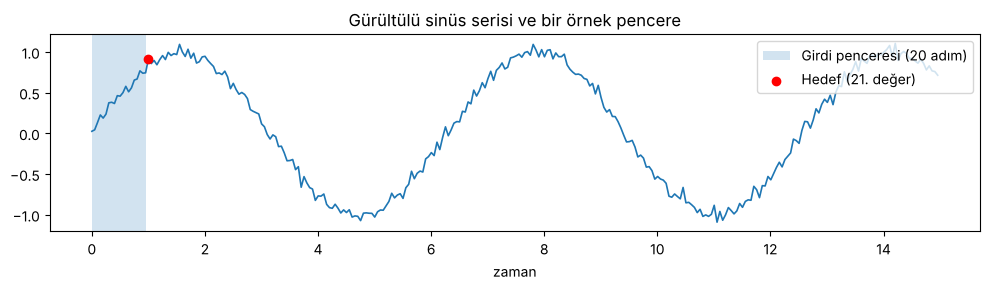

In [3]:
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(t[:300], seri[:300], lw=1.2)
ax.axvspan(t[0], t[PENCERE - 1], alpha=0.2, label="Girdi penceresi (20 adım)")
ax.scatter(t[PENCERE], seri[PENCERE], color="red", zorder=3, label="Hedef (21. değer)")
ax.set_title("Gürültülü sinüs serisi ve bir örnek pencere")
ax.set_xlabel("zaman"); ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

## 5. PyTorch ile GRU

### 5.1 Önce temel: GRU hücresini **elle** yazalım
LSTM'deki hileyi burada da kullanıyoruz: tek bir `Linear` katmanı `3H` boyutunda çıktı üretiyor, sonra bu çıktı 3 parçaya bölünüyor. PyTorch'taki kapı sırası **r, z, n** ($n$ = aday $\tilde{h}$).
Dikkat edilmesi gereken bir nokta var: $r_t$, $U_h h_{t-1}$ hesaplandıktan **sonra** uygulandığı için girdi ve gizli durum parçalarını ayrı ayrı tutmamız gerekiyor.

In [4]:
import torch                              # PyTorch çekirdeği
import torch.nn as nn                     # Hazır katmanlar
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)                     # Tekrarlanabilirlik

class ElleGRU(nn.Module):
    def __init__(self, girdi_boyutu, gizli_boyut):
        super().__init__()                                      # nn.Module kurucusu (zorunlu)
        self.H = gizli_boyut
        self.W_x = nn.Linear(girdi_boyutu, 3 * gizli_boyut)     # x_t → (W_r, W_z, W_n) tek seferde
        self.W_h = nn.Linear(gizli_boyut, 3 * gizli_boyut)      # h_{t-1} → (U_r, U_z, U_n) tek seferde

    def forward(self, x):                                       # x: (B, T, F)
        B, T, _ = x.shape
        h = torch.zeros(B, self.H)                              # h_0 = 0 (GRU'da hücre durumu yok)
        cikislar = []
        for t in range(T):                                      # Zamanda adım adım
            gx = self.W_x(x[:, t, :])                           # Girdinin katkısı: (B, 3H)
            gh = self.W_h(h)                                    # Geçmişin katkısı: (B, 3H)
            gx_r, gx_z, gx_n = gx.chunk(3, dim=1)               # 3 parçaya böl
            gh_r, gh_z, gh_n = gh.chunk(3, dim=1)
            r = torch.sigmoid(gx_r + gh_r)                      # Sıfırlama kapısı ∈ [0,1]
            z = torch.sigmoid(gx_z + gh_z)                      # Güncelleme kapısı ∈ [0,1]
            n = torch.tanh(gx_n + r * gh_n)                     # Aday: geçmişin katkısı r ile kısılır
            h = z * h + (1 - z) * n                             # Eski ile yeninin ağırlıklı ortalaması
            cikislar.append(h)
        return torch.stack(cikislar, dim=1), h                  # nn.GRU ile aynı dönüş biçimi

### 5.2 Elle yazdığımız hücre gerçekten `nn.GRU` ile aynı mı?

In [5]:
hazir = nn.GRU(input_size=1, hidden_size=32, batch_first=True)  # PyTorch'un hazır GRU'su
elle  = ElleGRU(girdi_boyutu=1, gizli_boyut=32)                  # Bizim hücremiz

with torch.no_grad():                                            # Ağırlıkları kopyala
    elle.W_x.weight.copy_(hazir.weight_ih_l0)                    # (3H, F)
    elle.W_x.bias.copy_(hazir.bias_ih_l0)                        # (3H,)
    elle.W_h.weight.copy_(hazir.weight_hh_l0)                    # (3H, H)
    elle.W_h.bias.copy_(hazir.bias_hh_l0)                        # (3H,)

ornek = torch.tensor(X_test_np[:4])                              # 4 test örneği
with torch.no_grad():
    cik_hazir, h_hazir = hazir(ornek)                            # Hazır GRU
    cik_elle,  h_elle  = elle(ornek)                             # Bizim GRU

print("Çıkış şekli :", tuple(cik_hazir.shape))                   # (4, 20, 32)
print("En büyük fark (tüm adımlar):", (cik_hazir - cik_elle).abs().max().item())
print("Aynı mı?", torch.allclose(cik_hazir, cik_elle, atol=1e-6))

Çıkış şekli : (4, 20, 32)
En büyük fark (tüm adımlar): 5.960464477539063e-08
Aynı mı? True


### 5.3 Veriyi tensöre çevirme ve DataLoader

In [6]:
X_egitim = torch.tensor(X_egitim_np)      # NumPy → tensör
y_egitim = torch.tensor(y_egitim_np)
X_test   = torch.tensor(X_test_np)
y_test   = torch.tensor(y_test_np)

egitim_yukleyici = DataLoader(
    TensorDataset(X_egitim, y_egitim),    # (girdi, hedef) çiftleri
    batch_size=64,                        # 64'lük mini-batch'ler
    shuffle=True)                         # Her epoch'ta karıştır

### 5.4 Asıl model: hazır `nn.GRU` katmanı
RNN modeliyle **tek fark** `nn.RNN` yerine `nn.GRU` yazılması. Dönüş değeri RNN'deki gibi `cikislar, h` şeklinde; LSTM'deki gibi `(h, c)` ikilisi değil.

In [7]:
class GRUModel(nn.Module):
    def __init__(self, girdi_boyutu=1, gizli_boyut=32, cikti_boyutu=1):
        super().__init__()
        self.gru = nn.GRU(                  # Hazır GRU katmanı
            input_size=girdi_boyutu,        # Her adımdaki özellik sayısı (1)
            hidden_size=gizli_boyut,        # Gizli durum boyutu H = 32
            num_layers=1,                   # Tek katman
            batch_first=True)               # Girdi şekli (B, T, F)
        self.fc = nn.Linear(gizli_boyut, cikti_boyutu)  # Son h_t → tahmin

    def forward(self, x):                   # x: (B, 20, 1)
        cikislar, h_son = self.gru(x)       # cikislar: (B,20,32); h_son: (1,B,32)
        son_adim = cikislar[:, -1, :]       # Son adımın gizli durumu: (B, 32)
        return self.fc(son_adim)            # (B, 32) → (B, 1)

model = GRUModel()
print(model)
print("Parametre sayısı:", sum(p.numel() for p in model.parameters()))
print("  GRU katmanı:", sum(p.numel() for p in model.gru.parameters()),
      "= 3 × (32·1 + 32·32 + 32 + 32)")

GRUModel(
  (gru): GRU(1, 32, batch_first=True)
  (fc): Linear(in_features=32, out_features=1, bias=True)
)
Parametre sayısı: 3393
  GRU katmanı: 3360 = 3 × (32·1 + 32·32 + 32 + 32)


### 5.5 Kayıp fonksiyonu, optimizer ve eğitim döngüsü
Döngü RNN ve LSTM ile **tamamen aynı**.

In [8]:
kayip_fn = nn.MSELoss()                     # Ortalama kare hata
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

EPOCH = 20
pt_kayiplar = []
for epoch in range(EPOCH):
    model.train()                           # Eğitim modu
    toplam_kayip = 0.0
    for xb, yb in egitim_yukleyici:
        optimizer.zero_grad()               # 1. Gradyanları sıfırla
        tahmin = model(xb)                  # 2. İleri yayılım
        kayip = kayip_fn(tahmin, yb)        # 3. Hata
        kayip.backward()                    # 4. BPTT
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)  # 5. Gradyan kırpma
        optimizer.step()                    # 6. Güncelle
        toplam_kayip += kayip.item() * len(xb)
    ort = toplam_kayip / len(X_egitim)
    pt_kayiplar.append(ort)
    print(f"Epoch {epoch + 1:2d}/{EPOCH} | eğitim MSE: {ort:.5f}")

Epoch  1/20 | eğitim MSE: 0.36489
Epoch  2/20 | eğitim MSE: 0.11494


Epoch  3/20 | eğitim MSE: 0.03387
Epoch  4/20 | eğitim MSE: 0.02239


Epoch  5/20 | eğitim MSE: 0.01619
Epoch  6/20 | eğitim MSE: 0.01263


Epoch  7/20 | eğitim MSE: 0.01008
Epoch  8/20 | eğitim MSE: 0.00801


Epoch  9/20 | eğitim MSE: 0.00609
Epoch 10/20 | eğitim MSE: 0.00432


Epoch 11/20 | eğitim MSE: 0.00381
Epoch 12/20 | eğitim MSE: 0.00363


Epoch 13/20 | eğitim MSE: 0.00362
Epoch 14/20 | eğitim MSE: 0.00354


Epoch 15/20 | eğitim MSE: 0.00352
Epoch 16/20 | eğitim MSE: 0.00357


Epoch 17/20 | eğitim MSE: 0.00365
Epoch 18/20 | eğitim MSE: 0.00349


Epoch 19/20 | eğitim MSE: 0.00350
Epoch 20/20 | eğitim MSE: 0.00351


### 5.6 Test

In [9]:
model.eval()
with torch.no_grad():
    pt_test_tahmin = model(X_test)
    pt_test_mse = kayip_fn(pt_test_tahmin, y_test).item()
print(f"PyTorch GRU Test MSE: {pt_test_mse:.5f}\n")

for i in range(5):
    print(f"Gerçek: {y_test[i].item():+.3f}   Tahmin: {pt_test_tahmin[i].item():+.3f}")

PyTorch GRU Test MSE: 0.00345

Gerçek: -1.016   Tahmin: -0.998
Gerçek: -1.032   Tahmin: -1.003
Gerçek: -0.968   Tahmin: -1.010
Gerçek: -0.880   Tahmin: -0.996
Gerçek: -0.930   Tahmin: -0.954


### 5.7 Kapıların içine bakalım
Eğitilmiş modelin bir test örneğindeki ortalama $r_t$ ve $z_t$ değerlerini çiziyoruz.

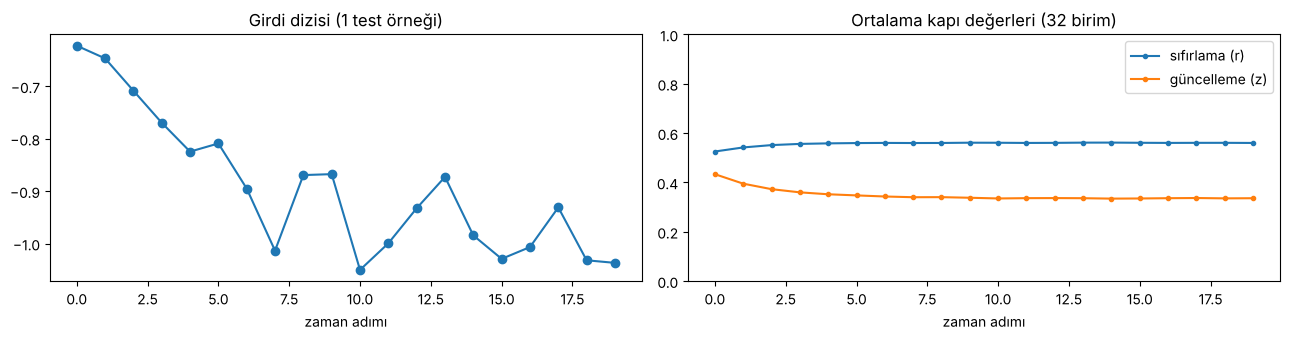

In [10]:
with torch.no_grad():
    Wih, Whh = model.gru.weight_ih_l0, model.gru.weight_hh_l0   # Eğitilmiş ağırlıklar
    bih, bhh = model.gru.bias_ih_l0, model.gru.bias_hh_l0
    x1 = X_test[0]                                              # Tek örnek: (20, 1)
    h = torch.zeros(32)
    kayit = {"sıfırlama (r)": [], "güncelleme (z)": []}
    for t_ in range(PENCERE):
        gx_r, gx_z, gx_n = (Wih @ x1[t_] + bih).chunk(3)
        gh_r, gh_z, gh_n = (Whh @ h + bhh).chunk(3)
        r = (gx_r + gh_r).sigmoid(); z = (gx_z + gh_z).sigmoid()
        n = (gx_n + r * gh_n).tanh()
        h = z * h + (1 - z) * n
        kayit["sıfırlama (r)"].append(r.mean().item())          # 32 birimin ortalaması
        kayit["güncelleme (z)"].append(z.mean().item())

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
ax[0].plot(x1[:, 0].numpy(), marker="o"); ax[0].set_title("Girdi dizisi (1 test örneği)")
ax[0].set_xlabel("zaman adımı")
for ad, deger in kayit.items():
    ax[1].plot(deger, marker=".", label=ad)
ax[1].set_ylim(0, 1); ax[1].set_title("Ortalama kapı değerleri (32 birim)")
ax[1].set_xlabel("zaman adımı"); ax[1].legend()
plt.tight_layout(); plt.show()

## 6. Keras ile GRU

Keras'ta yine **tek kelime** değişiyor: `SimpleRNN` / `LSTM` → `GRU`.
Keras'ın varsayılanı `reset_after=True`. Bu ayar PyTorch'la aynı formülü kullanır ve iki bias vektörü tutar, bu yüzden **parametre sayıları iki kütüphanede birebir aynı** çıkar.

In [11]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"  # TensorFlow bilgi mesajlarını gizle
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.random.set_seed(42)

keras_model = keras.Sequential([
    keras.Input(shape=(PENCERE, 1)),      # 20 zaman adımı × 1 özellik
    layers.GRU(
        32,                               # Gizli durum boyutu H = 32
        activation="tanh",                # Aday (h̃) aktivasyonu
        recurrent_activation="sigmoid",   # Kapıların (r, z) aktivasyonu
        reset_after=True,                 # r, U·h'den SONRA uygulanır (PyTorch ile aynı)
        return_sequences=False),          # Sadece son h_t (B, 32)
    layers.Dense(1)                       # Son h_t → tahmin
])
keras_model.summary()                     # GRU: 3 × (32·1 + 32·32) + 2 × 3 × 32 = 3360 parametre

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 32)             │         3,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,393 (13.25 KB)

 Trainable params: 3,393 (13.25 KB)

 Non-trainable params: 0 (0.00 B)

### 6.1 Derleme ve eğitim

In [12]:
keras_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3, clipnorm=1.0),  # Adam + gradyan kırpma
    loss="mse",
    metrics=["mae"])

gecmis = keras_model.fit(
    X_egitim_np, y_egitim_np,
    epochs=20,
    batch_size=64,
    validation_split=0.1,                 # %10 doğrulama
    shuffle=True,
    verbose=2)

Epoch 1/20


23/23 - 2s - 75ms/step - loss: 0.3035 - mae: 0.4818 - val_loss: 0.0996 - val_mae: 0.2841


Epoch 2/20


23/23 - 0s - 17ms/step - loss: 0.0396 - mae: 0.1730 - val_loss: 0.0255 - val_mae: 0.1352


Epoch 3/20


...

23/23 - 0s - 9ms/step - loss: 0.0036 - mae: 0.0482 - val_loss: 0.0040 - val_mae: 0.0526


Epoch 19/20


23/23 - 0s - 8ms/step - loss: 0.0036 - mae: 0.0479 - val_loss: 0.0040 - val_mae: 0.0523


Epoch 20/20


23/23 - 0s - 8ms/step - loss: 0.0035 - mae: 0.0476 - val_loss: 0.0040 - val_mae: 0.0520


### 6.2 Test

In [13]:
k_test_mse, k_test_mae = keras_model.evaluate(X_test_np, y_test_np, verbose=0)
print(f"Keras GRU Test MSE: {k_test_mse:.5f} | Test MAE: {k_test_mae:.5f}\n")

k_test_tahmin = keras_model.predict(X_test_np, verbose=0)
for gercek, tahmin in zip(y_test_np[:5, 0], k_test_tahmin[:5, 0]):
    print(f"Gerçek: {gercek:+.3f}   Tahmin: {tahmin:+.3f}")

Keras GRU Test MSE: 0.00342 | Test MAE: 0.04553



Gerçek: -1.016   Tahmin: -0.997
Gerçek: -1.032   Tahmin: -1.004
Gerçek: -0.968   Tahmin: -1.010
Gerçek: -0.880   Tahmin: -0.990
Gerçek: -0.930   Tahmin: -0.936


## 7. Karşılaştırma

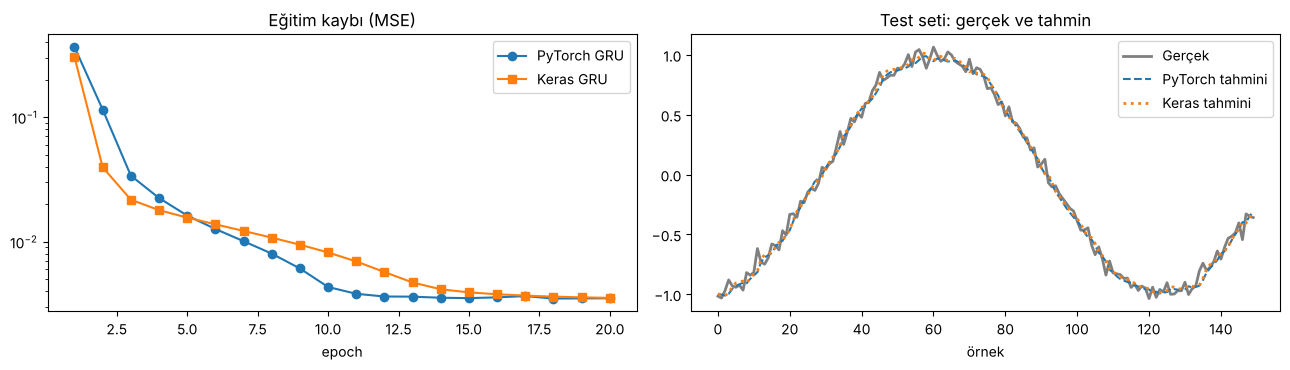

PyTorch GRU Test MSE: 0.00345
Keras   GRU Test MSE: 0.00342
Gürültünün kendi varyansı (alt sınır ≈): 0.00250


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))

axes[0].plot(range(1, 21), pt_kayiplar, marker="o", label="PyTorch GRU")
axes[0].plot(range(1, 21), gecmis.history["loss"], marker="s", label="Keras GRU")
axes[0].set_yscale("log")
axes[0].set_title("Eğitim kaybı (MSE)"); axes[0].set_xlabel("epoch"); axes[0].legend()

n = 150
axes[1].plot(y_test_np[:n, 0], color="black", lw=2, alpha=0.5, label="Gerçek")
axes[1].plot(pt_test_tahmin[:n, 0].numpy(), "--", label="PyTorch tahmini")
axes[1].plot(k_test_tahmin[:n, 0], ":", lw=2, label="Keras tahmini")
axes[1].set_title("Test seti: gerçek ve tahmin"); axes[1].set_xlabel("örnek"); axes[1].legend()

plt.tight_layout(); plt.show()

print(f"PyTorch GRU Test MSE: {pt_test_mse:.5f}")
print(f"Keras   GRU Test MSE: {k_test_mse:.5f}")
print(f"Gürültünün kendi varyansı (alt sınır ≈): {0.05**2:.5f}")

### RNN vs LSTM vs GRU — üç notebook'un özeti

Aynı veri, aynı görev, H=32, 20 epoch (değerler bu üç notebook'un çalıştırılmasından alındı; rastgelelik nedeniyle küçük farklar olabilir):

| | RNN | LSTM | GRU |
|---|---|---|---|
| Parametre (PyTorch) | 1 153 | 4 513 | 3 393 |
| Parametre (Keras) | 1 121 | 4 385 | 3 393 |
| Test MSE (PyTorch) | 0.0044 | 0.0036 | 0.0035 |
| Test MSE (Keras) | 0.0031 | 0.0029 | 0.0034 |

Gürültü kaynaklı alt sınır ≈ 0.0025. Üç model de bu sınıra yakın; bu kadar basit ve kısa bir görevde aralarındaki fark küçüktür. Kapılı modellerin (LSTM/GRU) asıl farkı **uzun dizilerde** ortaya çıkar.

### Kodda değişenler

| | RNN | LSTM | GRU |
|---|---|---|---|
| PyTorch katmanı | `nn.RNN` | `nn.LSTM` | `nn.GRU` |
| PyTorch dönüşü | `cikislar, h` | `cikislar, (h, c)` | `cikislar, h` |
| Keras katmanı | `SimpleRNN` | `LSTM` | `GRU` |
| Hafıza | $h_t$ | $h_t$ + $c_t$ | $h_t$ |
| Kapı sayısı | 0 | 3 (f, i, o) | 2 (r, z) |
| Güncelleme | $\tanh(\dots)$ ile tamamen yeniden yazma | $f\odot c + i\odot g$ | $z\odot h + (1-z)\odot\tilde{h}$ |
| Uzun bağımlılık | zayıf | güçlü | güçlü |
| Hız | en hızlı | en yavaş | ikisinin arası |

### Hangisini ne zaman seçmeli?
- **RNN:** Kısa diziler, öğrenme amaçlı çalışmalar, çok basit desenler.
- **LSTM:** Çok uzun bağımlılıklar ve büyük veri; ek kapasiteye ihtiyaç duyulduğunda.
- **GRU:** Daha az veri ya da daha az hesaplama gücü olduğunda iyi bir başlangıç noktasıdır. Çoğu zaman LSTM'e yakın sonuç verir ve daha hızlı eğitilir.

Pratikte ikisini de deneyip doğrulama hatasına bakmak en güvenilir yoldur. Bu notebook'taki kodda bu, **tek kelime** değiştirmek demektir.